# Purpose 
This simple code allows to quickly load and process images acquired from micro-manager
Under the hood it uses pycromanager (https://github.com/micro-manager/pycro-manager) 

In [1]:
import os,time
from mmpyreader import MMpyreader
import matplotlib.cm as cm 
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('image', cmap='gray') # set default cmap as gray
import numpy as np 

# A green colormap (for GFP)
import matplotlib
vals = np.linspace(0,1,256)
cols = vals*np.array([[0,1,0]]*256).T
cols = cols.T
gfpcmap = matplotlib.colors.ListedColormap(cols)
cmap = {'FITC-GFP':gfpcmap,'red filter':None}

In [2]:
# Setup the reader (if any issue with ZMQ check that micro-manager is running and the server setup on port XXXX)
# cf: 
reader = MMpyreader(verbose=True)
# Load our hyperstack
stack = reader.load_folder("/mnt/dioscuri-nas/Ola/2021.11.19_colonies2/_1/",virtual=True)

Bridge is opened on port 4827
230T x 4P x 2C x 21Z


You can get metadata informations like so:

In [5]:
# As an attribute for the few obvious ones
print(stack.channels)

# Or by calling the method with the java syntax (see: https://valelab4.ucsf.edu/~MM/doc-2.0.0-gamma/mmstudio/org/micromanager/data/SummaryMetadata.html)
print(stack._metadata.getChannelNameList())

['FITC-GFP', 'red filter']
['FITC-GFP', 'red filter']


In [6]:
# There are many more metadata 
print(f"Axes order: {stack._metadata.getOrderedAxes()}")
print(f"Acquisition run on: {stack._metadata.getStartDate()}")

Axes order: ['z', 'channel', 'position', 'time']
Acquisition run on: 2021-11-19 11:13:53.834 +0100


In [7]:
# List channels
print(f"Channels:\n {stack.channels}")
# List positions 
pos = stack._metadata.getStagePositionList()
print("Positions:")
for p in pos:
    print(f"{p.getLabel()}: X={p.getX()},Y={p.getY()},Z={p.getZ()}")

Channels:
 ['FITC-GFP', 'red filter']
Positions:
Pos1: X=13146.2,Y=-1297.6000000000001,Z=2985.2400000000002
Pos2: X=12742.400000000001,Y=-1178.2,Z=2983.84
Pos3: X=12783.6,Y=-283,Z=2986.02
Pos4: X=12792.2,Y=-1550.1000000000001,Z=2983.3


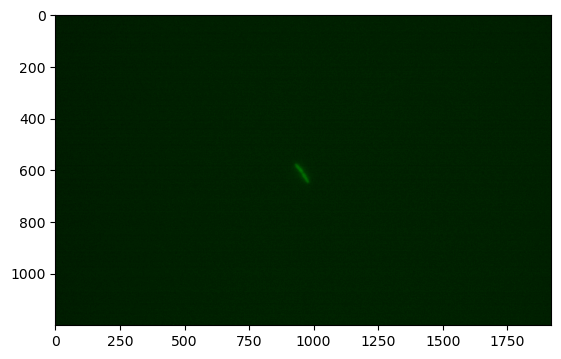

In [8]:
# Get a single image
img,img_meta = stack.get_img(C=0,P=0,T=0,Z=6)
plt.imshow(img,cmap=cmap['FITC-GFP'])

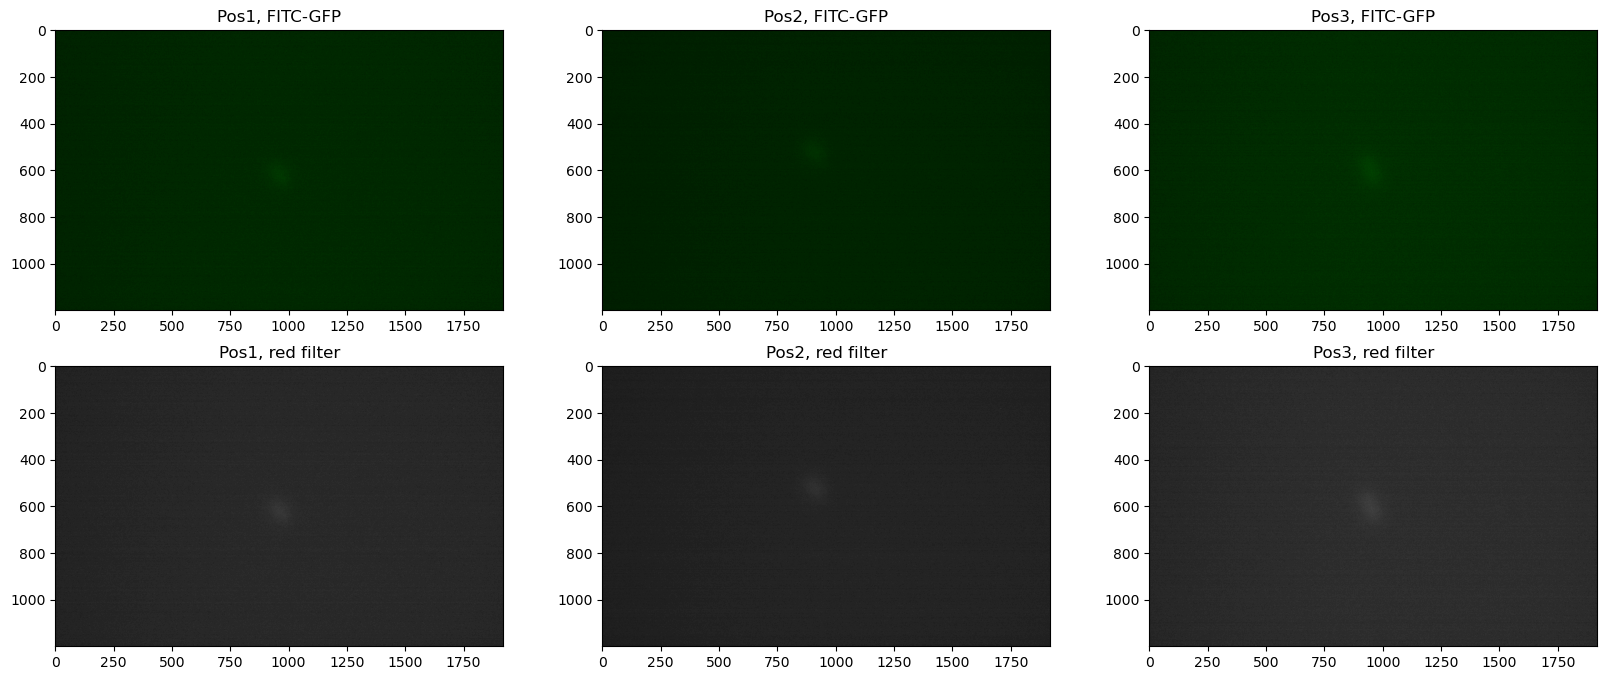

In [9]:
# Get a substack, if an element is not provided it is assumed you want 
# all elements, /!\ this is 0 indexed
# 6 elements, channel 0/1 and pos 0/1/2 
channels = stack.channels 
pos = ['Pos1','Pos2','Pos3'] # or  [0,1,2]
substack,substack_meta = stack.get_substack(C=channels,P=pos,T=1,Z=1)
fig,axs = plt.subplots(len(channels),len(pos),figsize=[20,8])
substack = substack.squeeze() # remove extra dims
for i,p in enumerate(pos): 
    # Channel 0 (GFP)
    axs[0][i].imshow(substack[i,0],cmap=gfpcmap,vmax=substack[i,0].max())
    axs[0][i].set_title(f'{pos[i]}, {stack.channels[0]}')
    # Channel 1 bright-field
    axs[1][i].imshow(substack[i,0])
    axs[1][i].set_title(f'{pos[i]}, {stack.channels[1]}')

In [10]:
%%time
# this is very fast even on the NAS 
zstack,ztack_meta = stack.get_substack(C=1,P=2,T=30) # Z stack

CPU times: user 76.4 ms, sys: 37.1 ms, total: 114 ms
Wall time: 551 ms
